In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import smlp

In [2]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [3]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

bow_encoder = clslib.BagOfWords(bpe_tokenizer.get_vocab(), bpe_tokenizer)

my_classifiers = OrderedDict()

In [4]:
# hidden_dim=128
# dropout=0.1
# batch_size=64
# learning_rate=1e-3
# weight_decay=1e-4
# num_epochs=10
# device='cpu'

# metrics_for_all, best_epoch, best_preds = smlp.train_neural_network_model(
#     my_cross_validation_sets[0][0]["training"],  # remember to index datasets by [run][fold]
#     my_cross_validation_sets[0][0]["validation"],  # remember to index datasets by [run][fold]
#     num_classes=1,
#     encoder=bow_encoder, 
#     save_to=f'{results_folder}/tmpmodel',
#     hidden_dim=hidden_dim, 
#     dropout=dropout, 
#     batch_size=batch_size, 
#     learning_rate=learning_rate,
#     weight_decay=weight_decay, 
#     num_epochs=num_epochs,
#     device='cpu'
# )

In [5]:
hidden_dim=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['singleMLP_bow-enc'] = []

for run, seed in enumerate(my_seeds):    
    run_folder = f"{results_folder}/singleMLP_bow-enc/seed-{seed}"
    my_classifiers['singleMLP_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=bow_encoder,
            model_option='smlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': hidden_dim, 
                'dropout': dropout, 
                'batch_size': batch_size, 
                'learning_rate': learning_rate, 
                'weight_decay': weight_decay, 
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 24.901 seconds
Dataloader done! Time taken: 0.427 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\PCUser\Desktop\UvA\NLP\NLP-Assignment-1\smlp.py:68: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.5107 | train acc: 0.7459 | val loss: 0.4195 | val acc: 0.8094
Epoch 02 | train loss: 0.3719 | train acc: 0.8374 | val loss: 0.3503 | val acc: 0.8496
Epoch 03 | train loss: 0.2916 | train acc: 0.8801 | val loss: 0.3028 | val acc: 0.8759
Epoch 04 | train loss: 0.2328 | train acc: 0.9096 | val loss: 0.2730 | val acc: 0.8922
Epoch 05 | train loss: 0.1892 | train acc: 0.9286 | val loss: 0.2567 | val acc: 0.8991
Epoch 06 | train loss: 0.1589 | train acc: 0.9422 | val loss: 0.2500 | val acc: 0.9027
Epoch 07 | train loss: 0.1356 | train acc: 0.9514 | val loss: 0.2464 | val acc: 0.9071
Epoch 08 | train loss: 0.1178 | train acc: 0.9589 | val loss: 0.2436 | val acc: 0.9121
Epoch 09 | train loss: 0.1030 | train acc: 0.9654 | val loss: 0.2469 | val acc: 0.9130
Epoch 10 | train loss: 0.0935 | train acc: 0.9680 | val loss: 0.2470 | val acc: 0.9143
Training done! Time taken: 95.235 seconds
Transforming documents...
Document transformation done! Time taken: 24.907 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5077 | train acc: 0.7496 | val loss: 0.4266 | val acc: 0.8131
Epoch 02 | train loss: 0.3715 | train acc: 0.8373 | val loss: 0.3617 | val acc: 0.8429
Epoch 03 | train loss: 0.2926 | train acc: 0.8788 | val loss: 0.3153 | val acc: 0.8671
Epoch 04 | train loss: 0.2353 | train acc: 0.9084 | val loss: 0.2851 | val acc: 0.8849
Epoch 05 | train loss: 0.1912 | train acc: 0.9293 | val loss: 0.2731 | val acc: 0.8921
Epoch 06 | train loss: 0.1601 | train acc: 0.9427 | val loss: 0.2627 | val acc: 0.8987
Epoch 07 | train loss: 0.1362 | train acc: 0.9517 | val loss: 0.2585 | val acc: 0.9041
Epoch 08 | train loss: 0.1185 | train acc: 0.9583 | val loss: 0.2528 | val acc: 0.9069
Epoch 09 | train loss: 0.1047 | train acc: 0.9643 | val loss: 0.2583 | val acc: 0.9081
Epoch 10 | train loss: 0.0924 | train acc: 0.9696 | val loss: 0.2620 | val acc: 0.9099
Training done! Time taken: 89.814 seconds
Transforming documents...
Document transformation done! Time taken: 25.186 seconds
Datal

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.5076 | train acc: 0.7503 | val loss: 0.4235 | val acc: 0.8054
Epoch 02 | train loss: 0.3690 | train acc: 0.8374 | val loss: 0.3550 | val acc: 0.8514
Epoch 03 | train loss: 0.2899 | train acc: 0.8826 | val loss: 0.3110 | val acc: 0.8742
Epoch 04 | train loss: 0.2294 | train acc: 0.9115 | val loss: 0.2789 | val acc: 0.8912
Epoch 05 | train loss: 0.1876 | train acc: 0.9297 | val loss: 0.2599 | val acc: 0.9014
Epoch 06 | train loss: 0.1566 | train acc: 0.9434 | val loss: 0.2570 | val acc: 0.9030
Epoch 07 | train loss: 0.1342 | train acc: 0.9536 | val loss: 0.2519 | val acc: 0.9070
Epoch 08 | train loss: 0.1175 | train acc: 0.9586 | val loss: 0.2566 | val acc: 0.9090
Epoch 09 | train loss: 0.1042 | train acc: 0.9646 | val loss: 0.2558 | val acc: 0.9106
Epoch 10 | train loss: 0.0924 | train acc: 0.9693 | val loss: 0.2626 | val acc: 0.9124
Training done! Time taken: 90.553 seconds


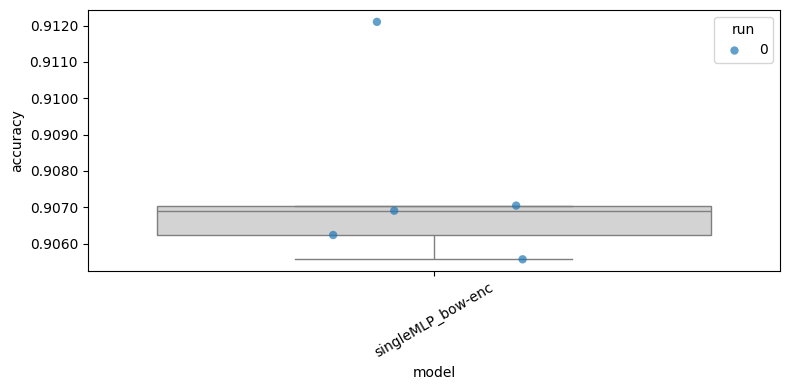

In [6]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [7]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [bow_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = smlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=smlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/singleMLP_bow-enc/seed-{seed}/fold-{fold}/model"
        model = smlp.load(model_folder)

        smlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = smlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.7158674537588697, 'accuracy': 0.7786697247706422}
              precision    recall  f1-score   support

           0       0.78      0.76      0.77       428
           1       0.78      0.79      0.78       444

    accuracy                           0.78       872
   macro avg       0.78      0.78      0.78       872
weighted avg       0.78      0.78      0.78       872

{'loss': 0.7169034809147546, 'accuracy': 0.7649082568807339}
              precision    recall  f1-score   support

           0       0.77      0.75      0.76       428
           1       0.76      0.78      0.77       444

    accuracy                           0.76       872
   macro avg       0.77      0.76      0.76       872
weighted avg       0.77      0.76      0.76       872

{'loss': 0.6996778020071327, 'accuracy': 0.7706422018348624}
              precision    recall  f1-score   support

           0       0.76      0.77      0.77       428
           1       0.78      0.77      0.77       444


In [8]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)